# Dynamische reactorrespons van het BEP

**Verkennende simulatie · eindige radiale diffusie · geen externe filmweerstand**

Deze notebook bouwt voort op de bestaande `pbr`-modules. Pas de configuratiecel aan om rooster, frequentie, modulatie en rekentoleranties te wijzigen. De notebook toont de invoer en uitlaat, axiale en radiale concentratieprofielen, een controle op periodieke ingeregeldheid en een gevoeligheidsvergelijking van pelletstraal `R`, effectieve diffusiviteit `D_e` en `R²/D_e`.

> **Reikwijdte.** De uitvoer is een reproduceerbare verkenning met het gecatalogiseerde literatuurmodel. Dit is geen kalibratie of experimentele validatie van Damian’s BEP. De herkomst en aannames staan hieronder bij het model.

## Fysica in deze berekening

- De gasconcentratie wordt langs het bed getransporteerd met plug flow. Axiale dispersie staat uit.
- De pellet is bolvormig en heeft eindige, celgecentreerde radiale volumes. In het centrum geldt symmetrie; op het oppervlak geldt `c_p(R,t) = C_b(z,t)`. Dit is de Dirichlet-grensvoorwaarde zonder externe filmweerstand.
- Met de porositeit-inclusieve diffusiviteit `D_e = ε_p D_m/τ` gebruikt de code in de poriën `D_e/ε_p`. De bulk en pellet wisselen dezelfde radiale oppervlaktestroom met tegengesteld teken uit. De reactie wordt één keer, in de pelletbalans, geteld.
- De Urmes-ratewet sluit de oppervlaktebedekking algebraïsch (quasi-stationair). De notebook modelleert dus geen vertraagde adsorptie/desorptie of dynamische katalysatorbedekking.

De natuurlijke diffusietijd van de gebruikte poriënvergelijking is **`τ_D = ε_p R²/D_e`**. De notebook toont ook de gevraagde kale verhouding `R²/D_e`; beide zijn zichtbaar, omdat `D_e` hier porositeit-inclusief is.

De laatste-periodetoets vergelijkt opeenvolgende uitlaatcurves op dezelfde fase. Een periodepaar slaagt wanneer voor iedere component de relatieve RMS-afwijking ten hoogste de ingestelde tolerantie is. Dit is een numerieke analyseheuristiek, geen experimenteel criterium.

In [1]:
from dataclasses import replace
from pathlib import Path
from time import perf_counter
import os
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "pbr").is_dir():
    REPO_ROOT = (REPO_ROOT / "..").resolve()
if not (REPO_ROOT / "pbr").is_dir():
    raise RuntimeError("Start this notebook from the Methanol-Catalysis repository")
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

from pbr import Inputs, build_model, effective_diffusivities, make_inlet
from pbr.parameters import AdvectionScheme
from pbr.parameter_sets import PROVENANCE
from pbr.species import GASES, Gas
from notebooks.bep_response_analysis import (
    analyse_settled_cycles,
    plot_axial_profiles,
    plot_cycle_overlay,
    plot_inlet_outlet,
    plot_parameter_comparison,
    plot_radial_heatmaps,
    plot_radial_profiles,
    sample_solution_by_period,
    set_plot_style,
)

set_plot_style()
SPECIES_NAMES = tuple(gas.value for gas in GASES)
FIGURE_DIR = Path("notebooks/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Eenvoudige configuratie

De startset `urmes2019` gebruikt gepubliceerde kinetiek en bedrijfscondities uit Urmes et al. De geometrie- en diffusieaannames zijn niet allemaal voor diezelfde katalysator gemeten; die zijn hieronder expliciet gemaakt. De lage roosterresolutie hieronder is bedoeld voor een vlotte, herhaalbare demonstratie.

In [2]:
# Bewerk deze waarden voor een eerste verkenning.
KINETIC_SET = "urmes2019"
N_AXIAL = 4
N_RADIAL = 5                 # aantal radiale controlevolumes
FORCING_HZ = 200.0
RELATIVE_MODULATION = 0.10   # cosinusmodulatie van alle gevolgde componenten
N_PERIODS = 12
SAMPLES_PER_PERIOD = 60
SETTLE_TOLERANCE = 0.01
SETTLE_REQUIRED_PAIRS = 3
METHOD = "BDF"
RTOL = 1e-4
ATOL = 1e-8

assert N_PERIODS >= SETTLE_REQUIRED_PAIRS + 1
PERIOD = 1.0 / FORCING_HZ

## Herkomst en aannames

De kinetische constanten, temperatuur, druk, voeding en debiet komen uit de Urmes 2019-set in `pbr`. De bestaande set koppelt die aan een reactorgeometrie die deels uit een andere bron komt. Daarom tonen we de overdracht en aannames apart in plaats van de hele configuratie als één gemeten BEP-installatie te presenteren.

- `R = 75 µm` is afgeleid als midden van de Urmes-zeefklasse 100–200 µm.
- `ε_p = 0,50`, `ρ_p = 1550 kg m⁻³`, `τ = 3,0` en `ε_b = 0,45` zijn als aannames geregistreerd; ze komen uit andere alumina-/packed-bed-bronnen.
- De buisdiameter 5 mm en katalysatormassa 75 mg komen uit de Larsen-reactorbron; de massa is in de registry als overgedragen aanname gemarkeerd.
- `D_e` is afgeleid met Fuller–Schettler–Giddings uit temperatuur, druk en gasparen, daarna vermenigvuldigd met `ε_p/τ`. Dit is geen gemeten diffusiviteit van de BEP-pellet.
- De opgelegde cosinus schaalt alle vier gevolgde gasconcentraties met dezelfde relatieve amplitude. Argon is geen toestand in `pbr` en blijft impliciet als balansgas.

Vóór de modelkeuze heb ik de projectmanagementbranch `research/bep-K-results-review-2026-10-18` op commit `e58d804` gecontroleerd. Issue #58 meldde dat de wetenschappelijke werkagent nog niet was gestart; er was geen Agent-A-handoff beschikbaar. De modelkeuze volgt daarom de bestaande `pbr`-implementatie en de hieronder beschreven tests.

In [3]:
assumption_names = (
    "catalyst.particle_radius",
    "catalyst.particle_porosity",
    "catalyst.particle_density",
    "catalyst.tortuosity",
    "geometry.tube_inner_diameter",
    "geometry.catalyst_mass",
    "geometry.bed_void_fraction",
    "transport.effective_diffusivity",
    "transport.external_film",
    "transport.axial_dispersion",
)
rows = [
    (name, PROVENANCE[name].source.value, PROVENANCE[name].reference,
     PROVENANCE[name].locator, PROVENANCE[name].note)
    for name in assumption_names
]
header = "| Grootheid | Status | Bron | Locatie | Toelichting |\n|---|---|---|---|---|"
body = "\n".join(
    f"| `{name}` | {kind} | `{source}` | {locator} | {note} |"
    for name, kind, source, locator, note in rows
)
display(Markdown(header + "\n" + body))

| Grootheid | Status | Bron | Locatie | Toelichting |
|---|---|---|---|---|
| `catalyst.particle_radius` | derived | `urmesKineticStudySelective2019` | Table 1, sieve fraction 100-200 um | radius = 150 um / 2 = 75 um, the midpoint of the fraction |
| `catalyst.particle_porosity` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 pellet porosity | transferred from an Na/gamma-Al2O3 sorbent, not from this catalyst |
| `catalyst.particle_density` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 particle density | 1550 kg/m3, an alumina pellet from a different study |
| `catalyst.tortuosity` | assumed | `dehghaniExperimentalApproachIndustrial2019` | reactor description | tau = 2.5 reported there; 3.0 used here as an alumina-typical value |
| `geometry.tube_inner_diameter` | literature | `larsenSemihydrogenationAcetyleneEthylene2024` | Appendix F | 5.0 mm |
| `geometry.catalyst_mass` | assumed | `larsenSemihydrogenationAcetyleneEthylene2024` | Appendix F, W_cat | 75 mg is the source's Pd2Ag bed; kept for the reactor match |
| `geometry.bed_void_fraction` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 | 0.45 is the assumed working value; 0.50 is reported for a packed alumina bed in a different study and is contextual only |
| `transport.effective_diffusivity` | derived | `fullerSchettlerGiddings1966` | Eq. for gas-phase diffusivity | D_e = eps_p D_m / tau with D_m from the Fuller correlation; pressure is converted from Pa to atm and D from cm^2/s to m^2/s |
| `transport.external_film` | derived | `urmesKineticStudySelective2019` | Table 7, Carberry 3.3e-4 | Ca << 0.05 at this catalyst, so the film closure is inactive by default |
| `transport.axial_dispersion` | derived | `danckwertsContinuousFlowSystems1953` | Eq. 30 | D_Lu = 0.018 of u_s*d_p; the closure defaults to zero (plug flow) |

## Model opbouwen en periodieke invoer opleggen

De beginstaat is een uniform bed en pellet met de invoerconcentratie op fase nul (de cosinuspiek). De eerste perioden bevatten daarom ook de overgang naar periodiek bedrijf; de laatste-periodetoets controleert of die invloed is verdwenen.

In [4]:
base_inputs = Inputs.catalogued(KINETIC_SET)
solver = base_inputs.solver.model_copy(
    update={
        "n_axial": N_AXIAL,
        "n_radial": N_RADIAL,
        "radial_geometry": 2,
        "advection_scheme": AdvectionScheme.TVD2,
        "integrator": METHOD,
        "rtol": RTOL,
        "atol": ATOL,
        "max_step": PERIOD / 10.0,
        "use_sparsity": True,
    }
)
base_inputs = replace(base_inputs, solver=solver)
BASE_DIFFUSIVITIES = effective_diffusivities(base_inputs.catalyst, base_inputs.operating)


def run_case(radius_factor=1.0, diffusivity_factor=1.0):
    """Build and integrate one radius/diffusivity sensitivity case."""
    catalyst = base_inputs.catalyst.model_copy(
        update={"particle_radius": base_inputs.catalyst.particle_radius * radius_factor}
    )
    case_inputs = replace(base_inputs, catalyst=catalyst)
    inlet = make_inlet(
        case_inputs.operating,
        forcing=[(FORCING_HZ, RELATIVE_MODULATION)],
    )
    diffusivities = {
        gas: value * diffusivity_factor
        for gas, value in BASE_DIFFUSIVITIES.items()
    }
    model = build_model(case_inputs, inlet, diffusivities=diffusivities)

    c0 = np.broadcast_to(inlet(0.0), (N_AXIAL, len(GASES))).copy()
    cp0 = np.broadcast_to(
        c0[:, None, :], (N_AXIAL, N_RADIAL, len(GASES))
    ).copy()
    y0 = model.layout.pack(c0, cp0, None)

    started = perf_counter()
    solution = model.integrate(
        y0,
        (0.0, N_PERIODS * PERIOD),
        method=METHOD,
        rtol=RTOL,
        atol=ATOL,
        max_step=PERIOD / 10.0,
        use_sparsity=True,
        dense_output=True,
    )
    elapsed = perf_counter() - started
    if not solution.success:
        raise RuntimeError(solution.message)
    trajectory, phase = sample_solution_by_period(
        model,
        solution,
        start_time=0.0,
        period=PERIOD,
        n_periods=N_PERIODS,
        samples_per_period=SAMPLES_PER_PERIOD,
    )
    return {
        "model": model,
        "solution": solution,
        "trajectory": trajectory,
        "phase": phase,
        "elapsed_s": elapsed,
        "radius_factor": radius_factor,
        "diffusivity_factor": diffusivity_factor,
    }


baseline = run_case()
print(f"Status: {baseline['solution'].message}")
print(f"Integratietijd: {baseline['elapsed_s']:.2f} s · nfev={baseline['solution'].nfev}")
print(
    "Concentratiebereik over solverstappen: "
    f"{baseline['solution'].y.min():.4g}–{baseline['solution'].y.max():.4g} mol m⁻³"
)

Status: The solver successfully reached the end of the integration interval.
Integratietijd: 0.20 s · nfev=509
Concentratiebereik over solverstappen: 0–36.01 mol m⁻³


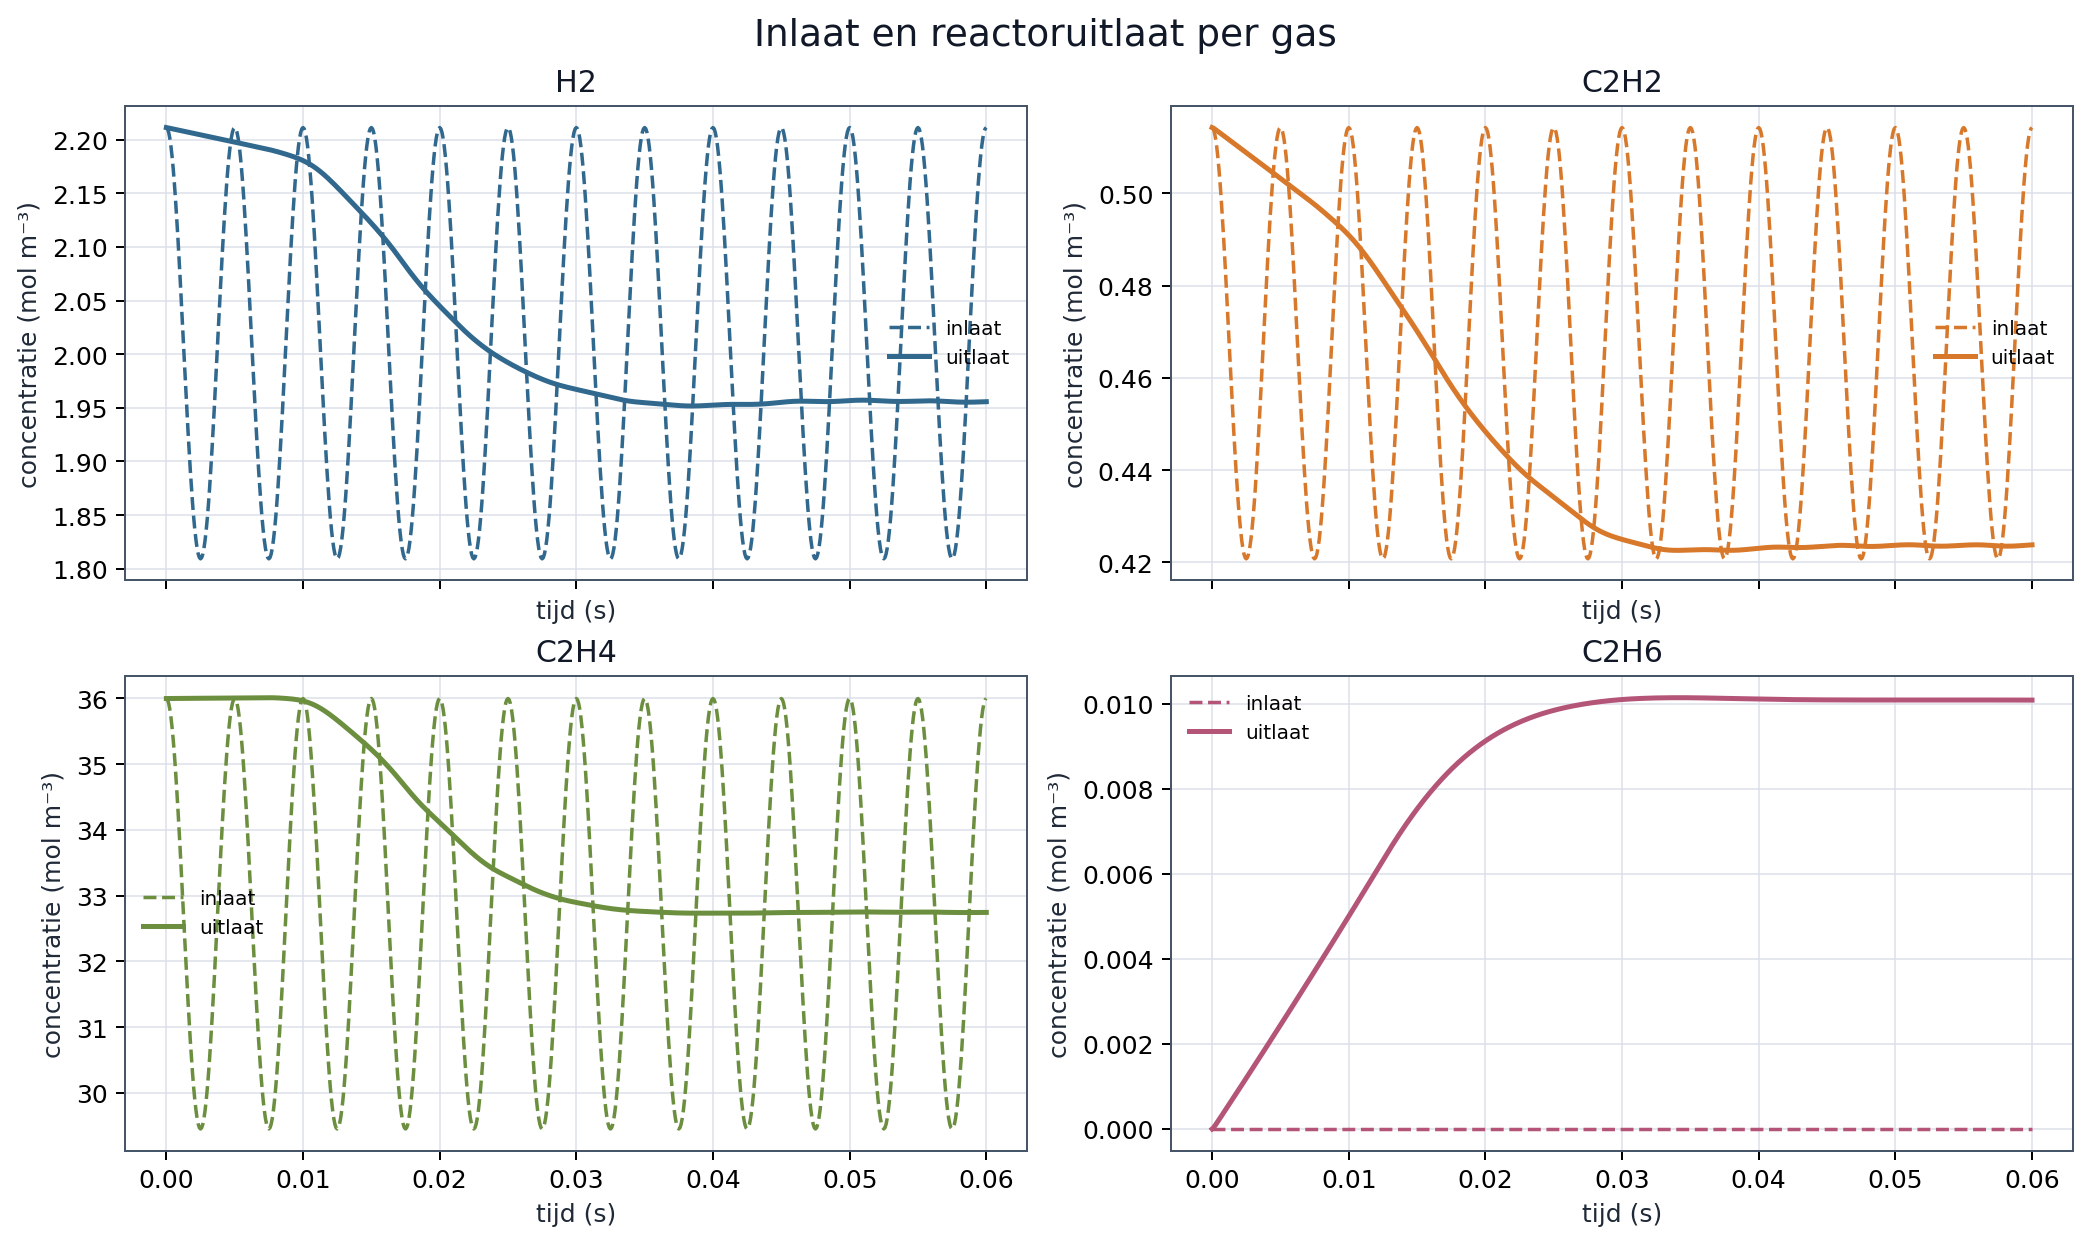

Figuur opgeslagen: notebooks/figures/inlet_outlet.png


In [5]:
def export_figure(figure, filename):
    path = FIGURE_DIR / filename
    figure.savefig(path, dpi=180, bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(figure)
    print(f"Figuur opgeslagen: {path}")


full_time = baseline["trajectory"].time.reshape(-1)
full_inlet = baseline["trajectory"].inlet.reshape(-1, len(GASES))
full_bulk = baseline["trajectory"].bulk.reshape(-1, N_AXIAL, len(GASES))
figure, _ = plot_inlet_outlet(full_time, full_inlet, full_bulk, SPECIES_NAMES)
export_figure(figure, "inlet_outlet.png")

## Axiale profielen

De curves zijn uit de laatste berekende periode gekozen. De posities zijn de centra van de axiale cellen.

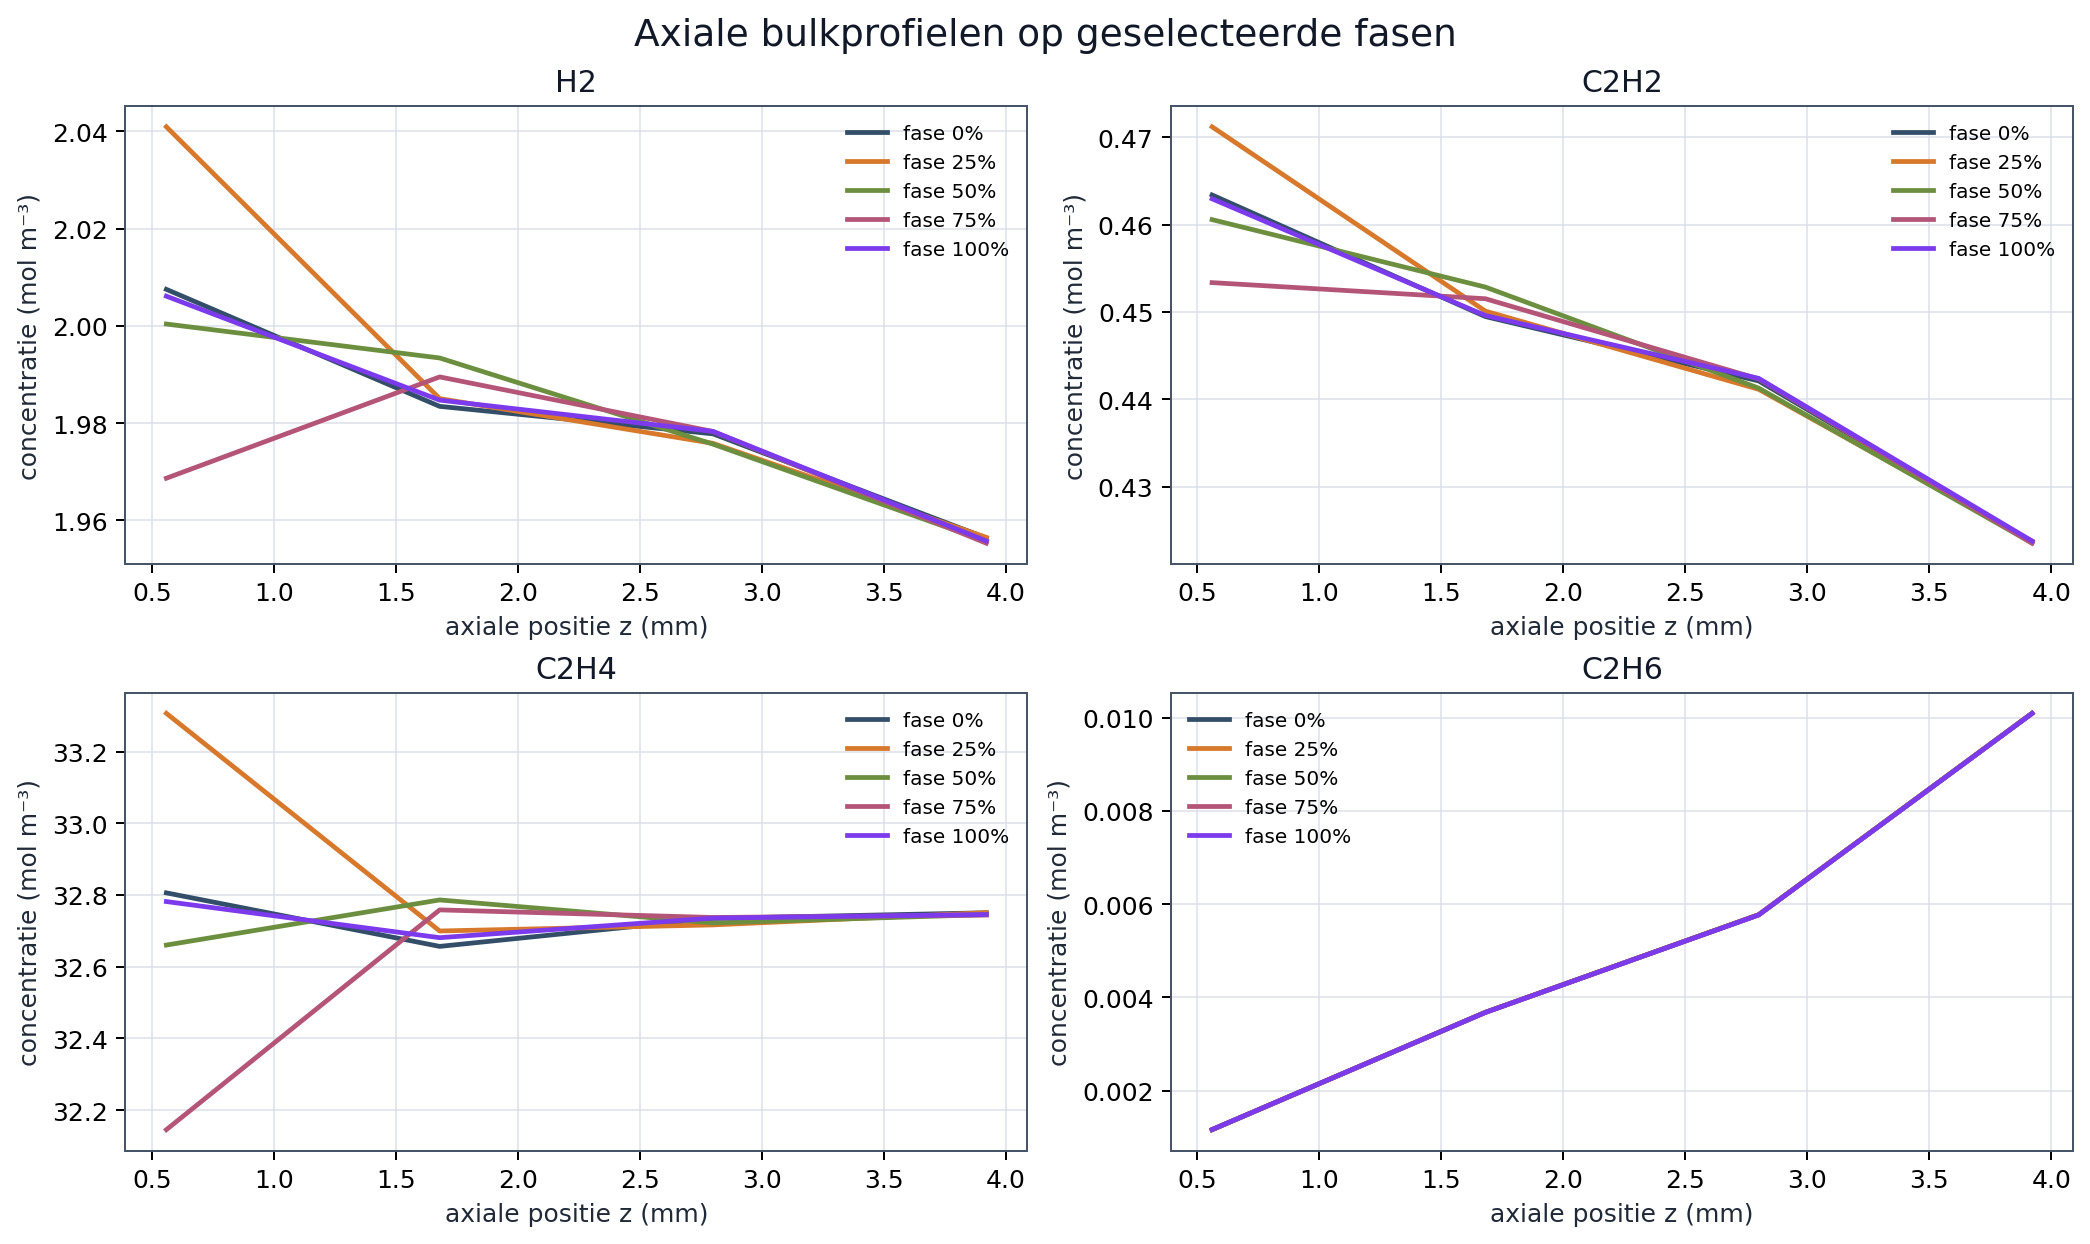

Figuur opgeslagen: notebooks/figures/axial_profiles.png


In [6]:
phase = baseline["phase"]
phase_indices = np.unique(np.linspace(0, SAMPLES_PER_PERIOD, 5, dtype=int))
phase_labels = tuple(
    f"fase {100 * index / SAMPLES_PER_PERIOD:.0f}%" for index in phase_indices
)
z_centers = (np.arange(N_AXIAL) + 0.5) * baseline["model"].derived.dz
bulk_snapshots = baseline["trajectory"].bulk[-1, phase_indices]
figure, _ = plot_axial_profiles(z_centers, bulk_snapshots, SPECIES_NAMES, phase_labels)
export_figure(figure, "axial_profiles.png")

## Radiale pelletprofielen

De lijnplot toont de celgemiddelden op dezelfde fasen als de axiale figuur, bij de laatste axiale cel. De heatmap toont de volledige laatste periode. De celcentra liggen binnen `r/R < 1`; op `r/R = 1` wordt de oppervlaktestaat algebraïsch gelijk aan het bulk gas gezet.

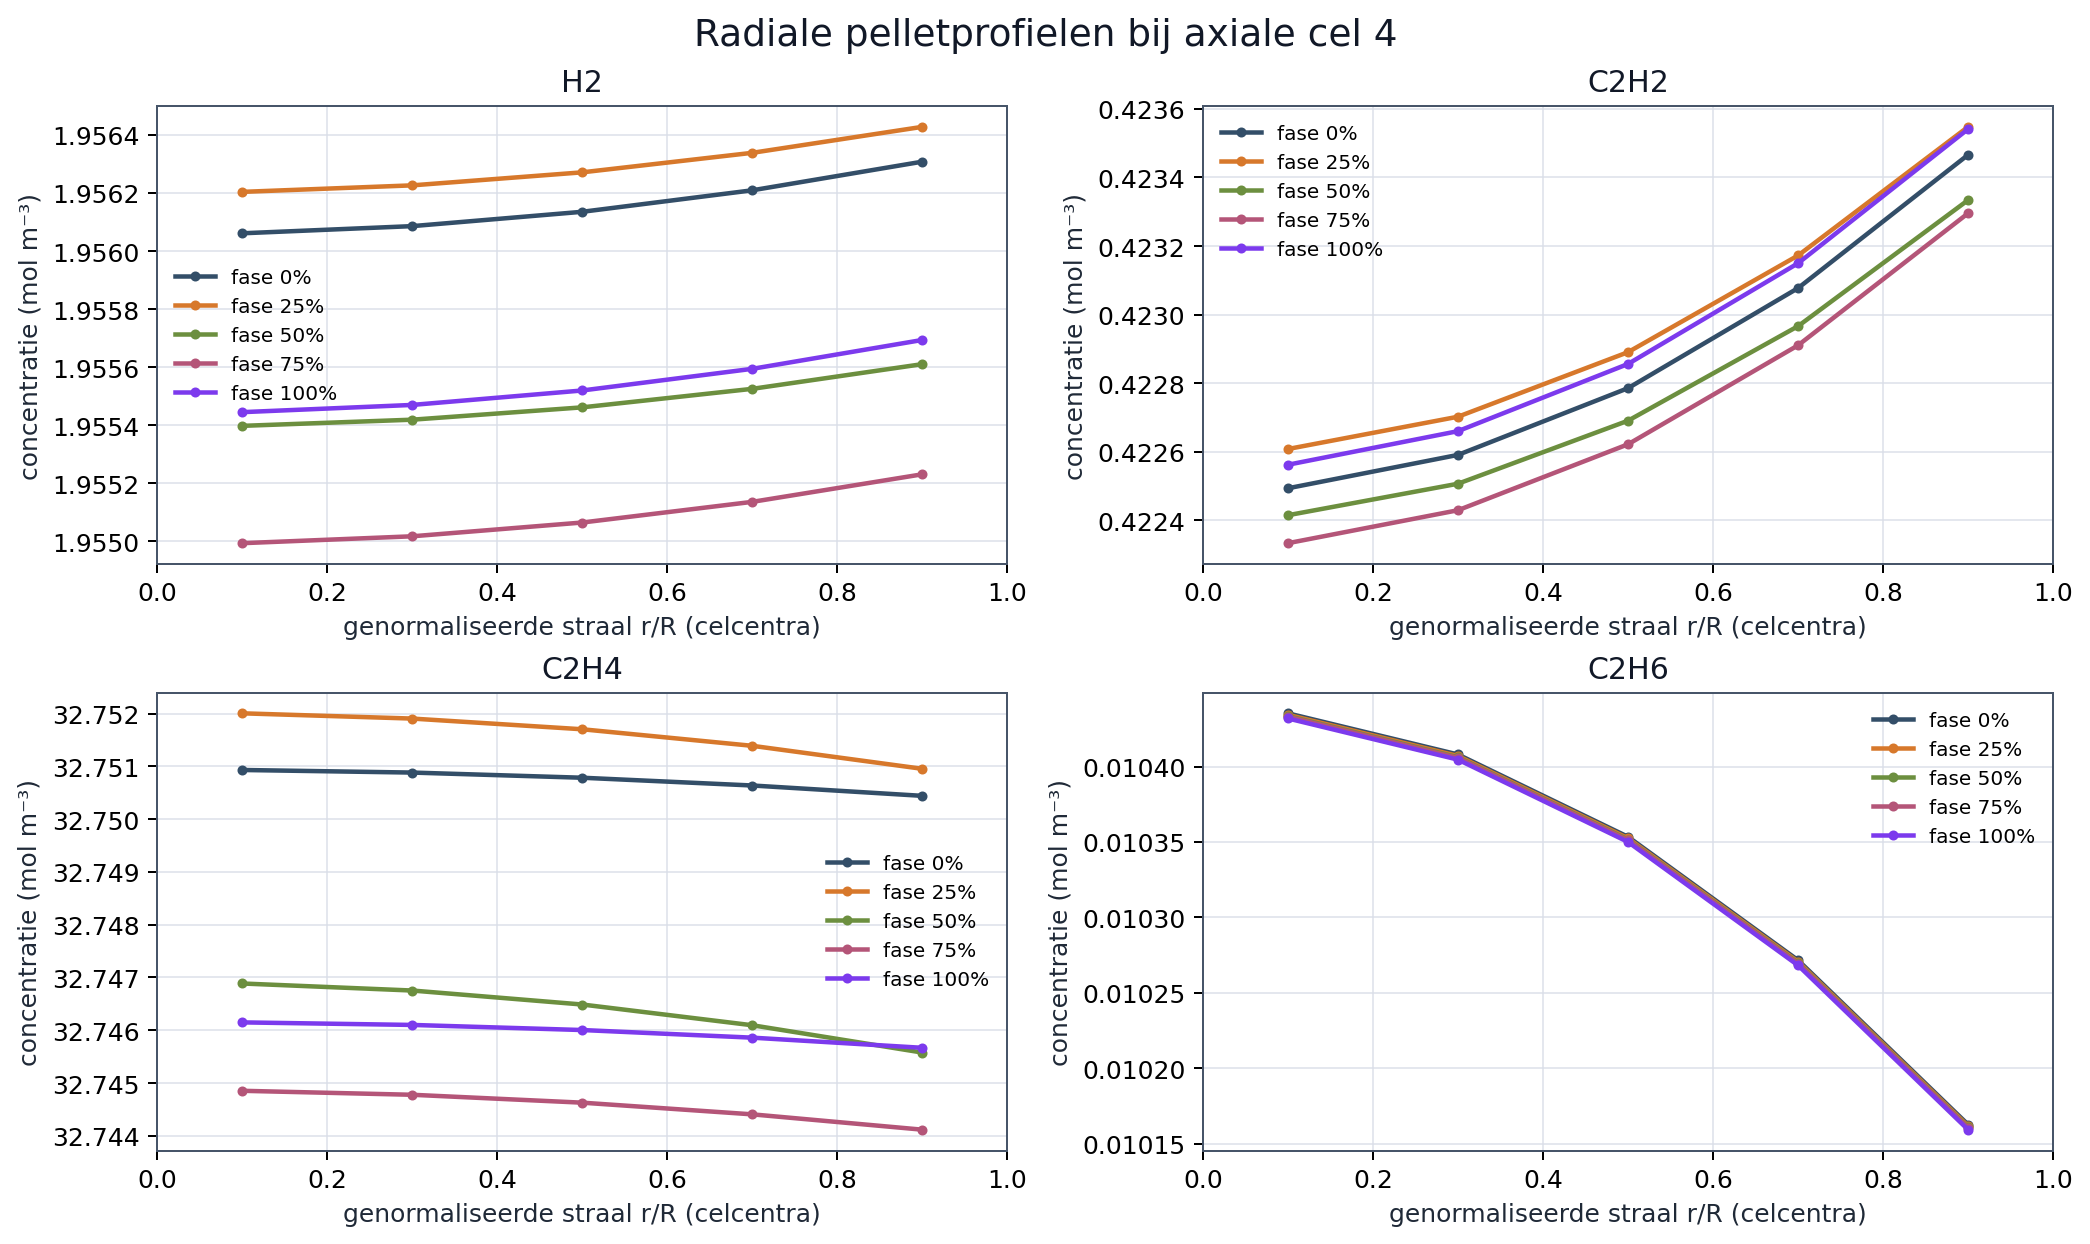

Figuur opgeslagen: notebooks/figures/radial_profiles.png


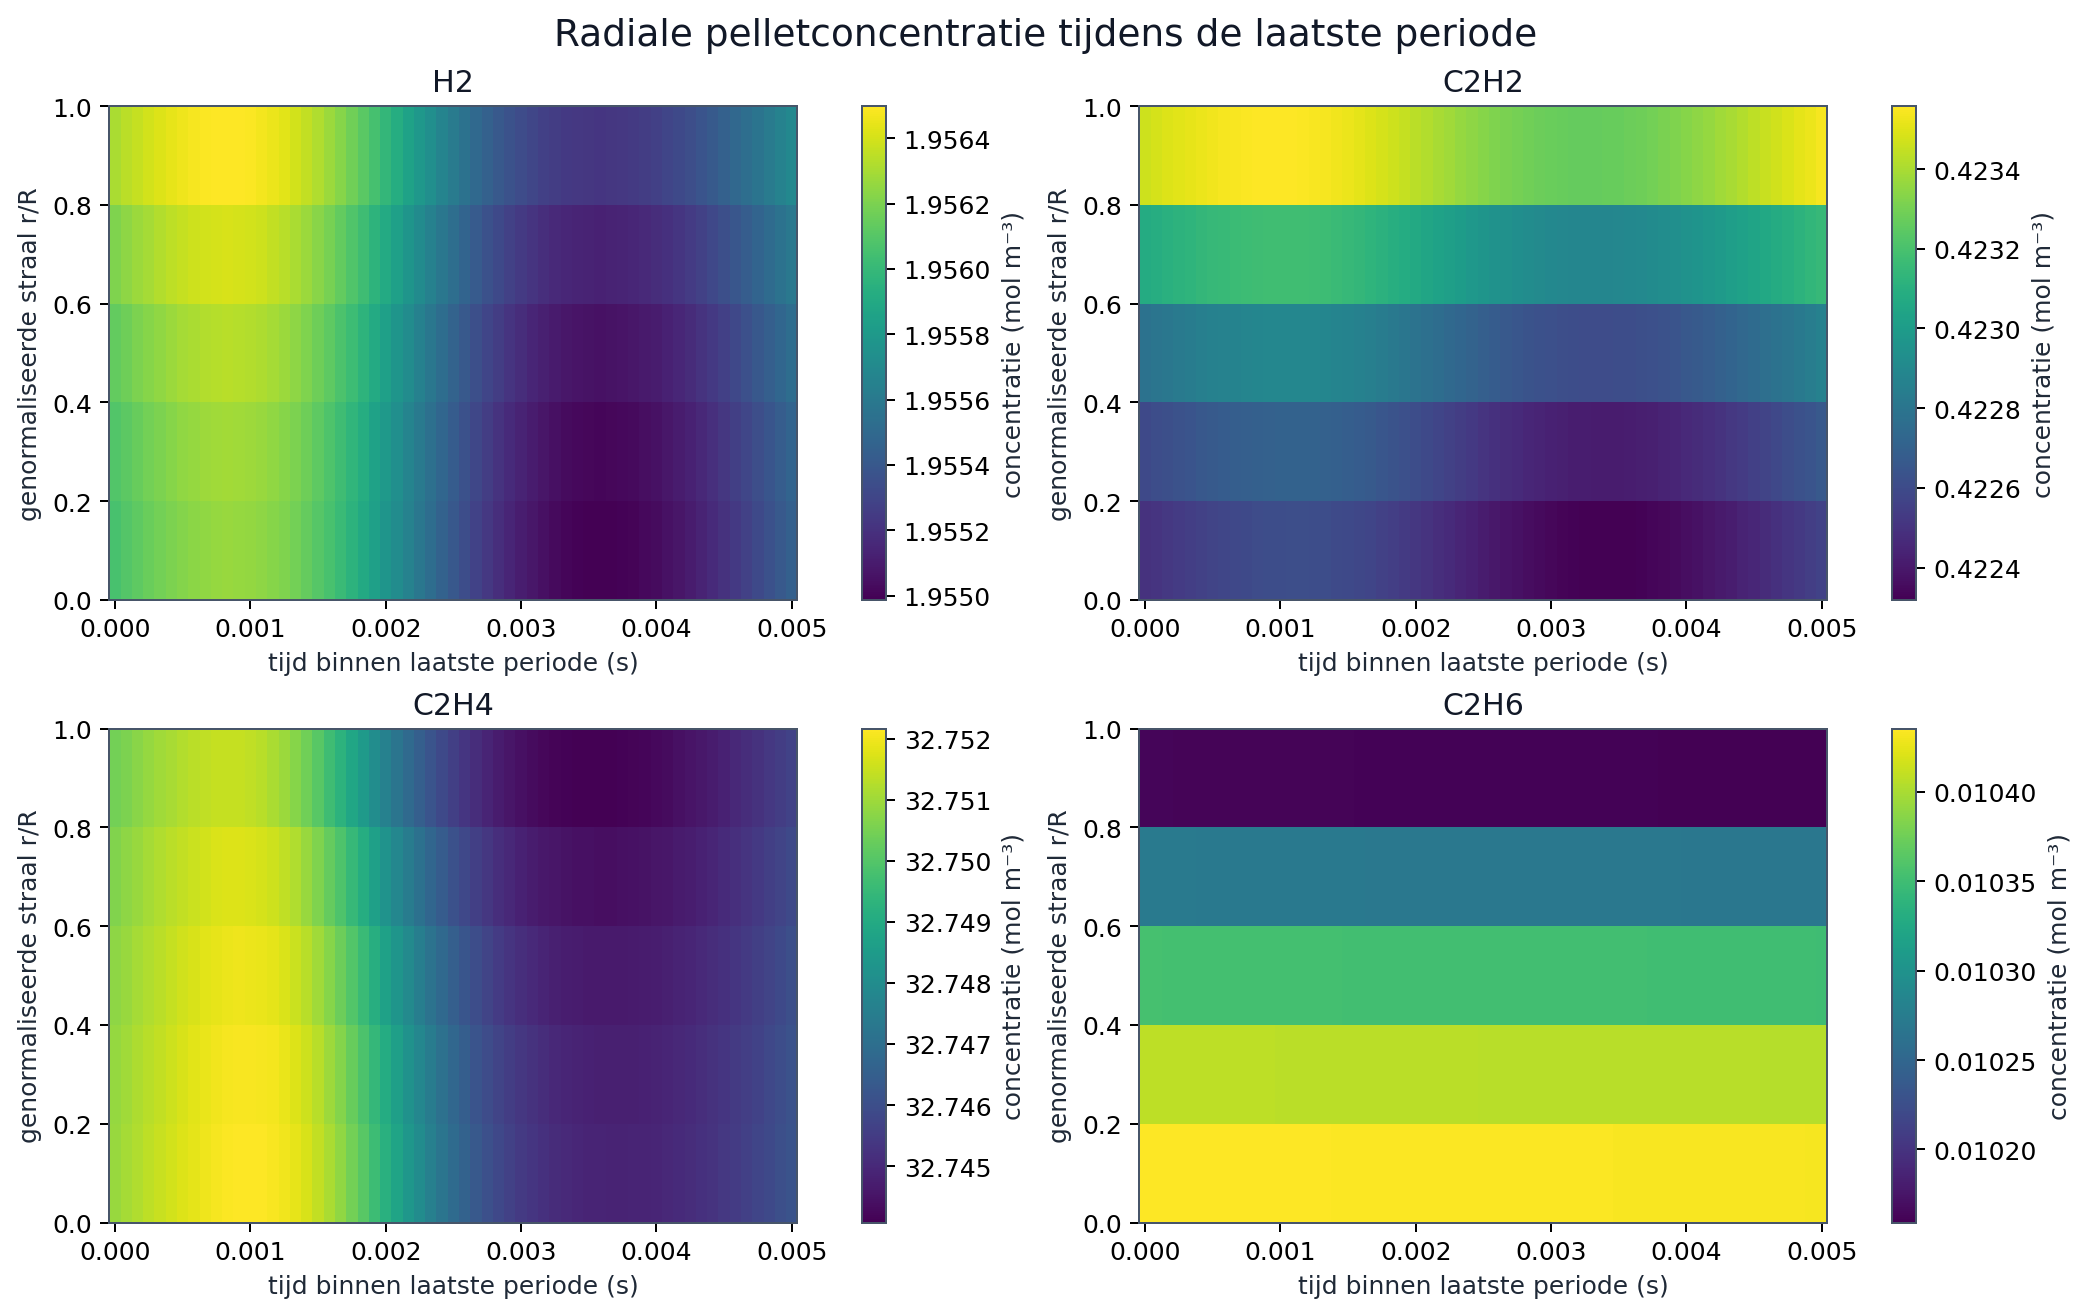

Figuur opgeslagen: notebooks/figures/radial_heatmaps.png


In [7]:
radius_fraction = baseline["model"].grid.r / baseline["model"].grid.r_p
particle_snapshots = baseline["trajectory"].particle[-1, phase_indices]
figure, _ = plot_radial_profiles(
    radius_fraction, particle_snapshots, N_AXIAL - 1, SPECIES_NAMES, phase_labels
)
export_figure(figure, "radial_profiles.png")

figure, _ = plot_radial_heatmaps(
    phase,
    radius_fraction,
    baseline["trajectory"].particle[-1],
    N_AXIAL - 1,
    SPECIES_NAMES,
)
export_figure(figure, "radial_heatmaps.png")

## Zijn de laatste perioden ingeregeld?

Hieronder worden opeenvolgende uitlaatperioden fase-op-fase vergeleken. De beslissing gebruikt `SETTLE_TOLERANCE` voor **alle** gevolgde gassen en vereist `SETTLE_REQUIRED_PAIRS` opeenvolgende slagende vergelijkingen. Bij onvoldoende perioden luidt de uitkomst expliciet dat ingeregeldheid niet is aangetoond.

Uitkomst: ingeregeld volgens de ingestelde heuristiek
Opeenvolgende slagende periodeparen aan het einde: 5
Start van de aaneengesloten ingeregelde suffix: periode 7
Tolerantie per gas: 1.00% relatieve RMS


| Periode | Gemiddelde C₂H₂ | Halve piek-piek C₂H₂ | Gemiddelde C₂H₄ |
|---:|---:|---:|---:|
| 10 | 0.42357 | 0.00013206 | 32.747 |
| 11 | 0.42365 | 0.00015432 | 32.75 |
| 12 | 0.42366 | 0.00014773 | 32.747 |

Eenheid: mol m⁻³.

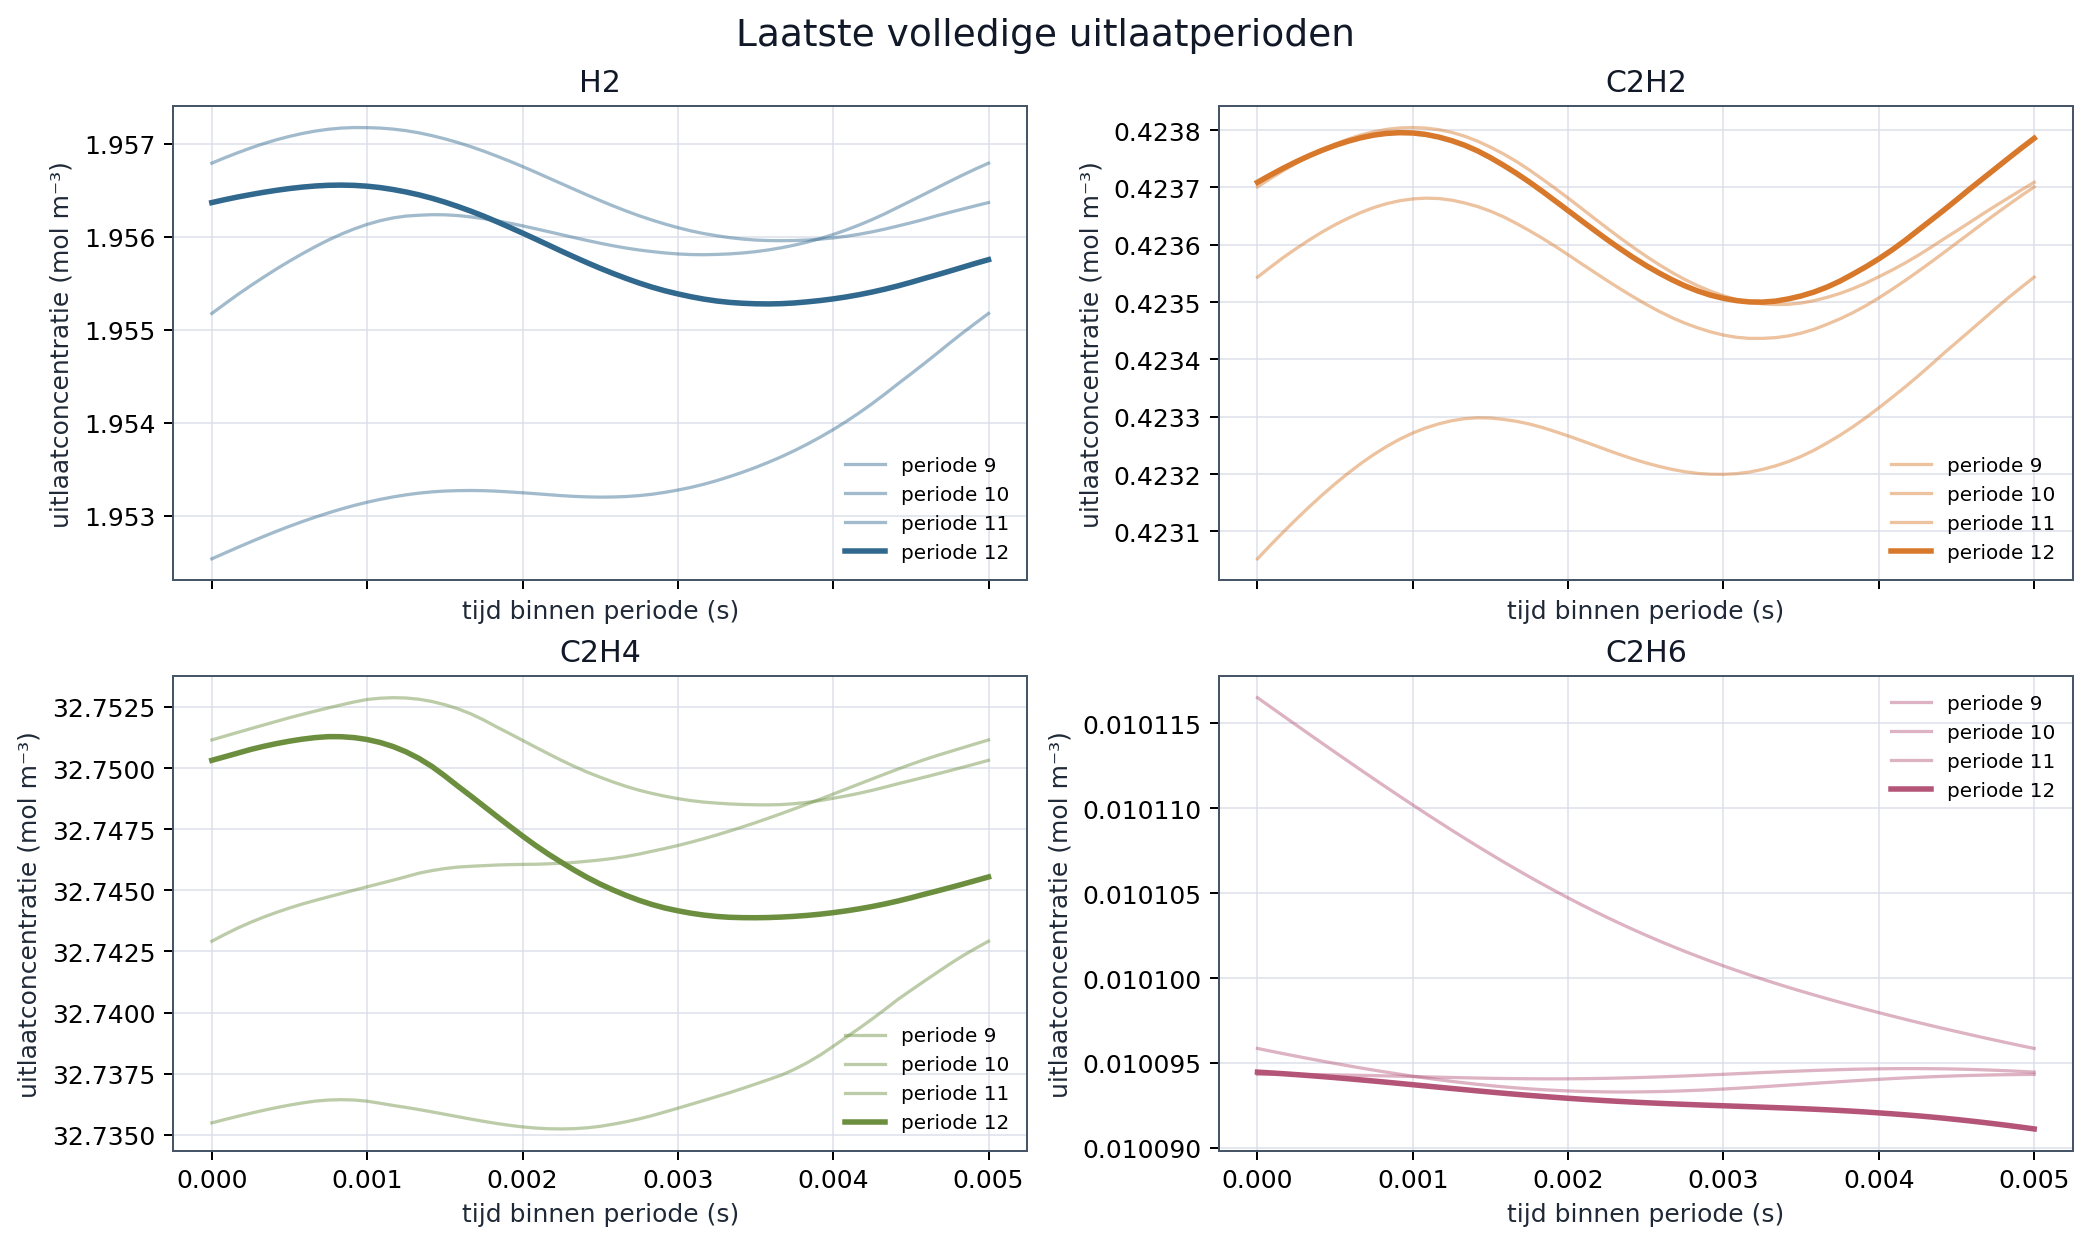

Figuur opgeslagen: notebooks/figures/last_cycles.png


In [8]:
outlet_by_cycle = baseline["trajectory"].bulk[:, :, -1, :]
settling = analyse_settled_cycles(
    outlet_by_cycle,
    phase,
    SPECIES_NAMES,
    relative_tolerance=SETTLE_TOLERANCE,
    required_consecutive_pairs=SETTLE_REQUIRED_PAIRS,
    periods_to_summarise=3,
)

status = "ingeregeld volgens de ingestelde heuristiek" if settling.settled else "niet aangetoond"
print(f"Uitkomst: {status}")
print(f"Opeenvolgende slagende periodeparen aan het einde: {settling.converged_pairs_at_end}")
if settling.first_settled_cycle is not None:
    print(f"Start van de aaneengesloten ingeregelde suffix: periode {settling.first_settled_cycle + 1}")
print(f"Tolerantie per gas: {100 * SETTLE_TOLERANCE:.2f}% relatieve RMS")

if settling.settled:
    header = "| Periode | Gemiddelde C₂H₂ | Halve piek-piek C₂H₂ | Gemiddelde C₂H₄ |\n|---:|---:|---:|---:|"
    body = "\n".join(
        f"| {row['cycle']} | {row['mean']['C2H2']:.5g} | "
        f"{row['half_peak_to_peak']['C2H2']:.5g} | {row['mean']['C2H4']:.5g} |"
        for row in settling.summary_cycles
    )
    display(Markdown(header + "\n" + body + "\n\nEenheid: mol m⁻³."))

last_cycles = tuple(range(max(0, N_PERIODS - 4), N_PERIODS))
figure, _ = plot_cycle_overlay(phase, outlet_by_cycle, SPECIES_NAMES, last_cycles)
export_figure(figure, "last_cycles.png")

## Gevoeligheid voor `R`, `D_e` en `R²/D_e`

Deze vier gevallen zijn gecontroleerde schaalvarianten van dezelfde startset; het zijn **geen gemeten pelletalternatieven**. Alle gasspecies krijgen dezelfde `D_e`-schaalfactor. Bij vaste porositeit en geometrie veranderen de paren `R×2, D×1` en `R×1, D×0,25` beide `R²/D_e` met factor vier. Het paar `R×2, D×4` houdt `R²/D_e` gelijk aan de basis. In dit model zonder filmweerstand en met dezelfde reactiestructuur horen de gelijke `R²/D_e`-gevallen vrijwel samen te vallen.

Basis · R×1, D×1: 0.20 s · nfev=509 · min C=0 mol m⁻³


R×2, D×1: 0.18 s · nfev=471 · min C=0 mol m⁻³


R×1, D×0,25: 0.20 s · nfev=471 · min C=0 mol m⁻³


R×2, D×4: 0.21 s · nfev=509 · min C=0 mol m⁻³


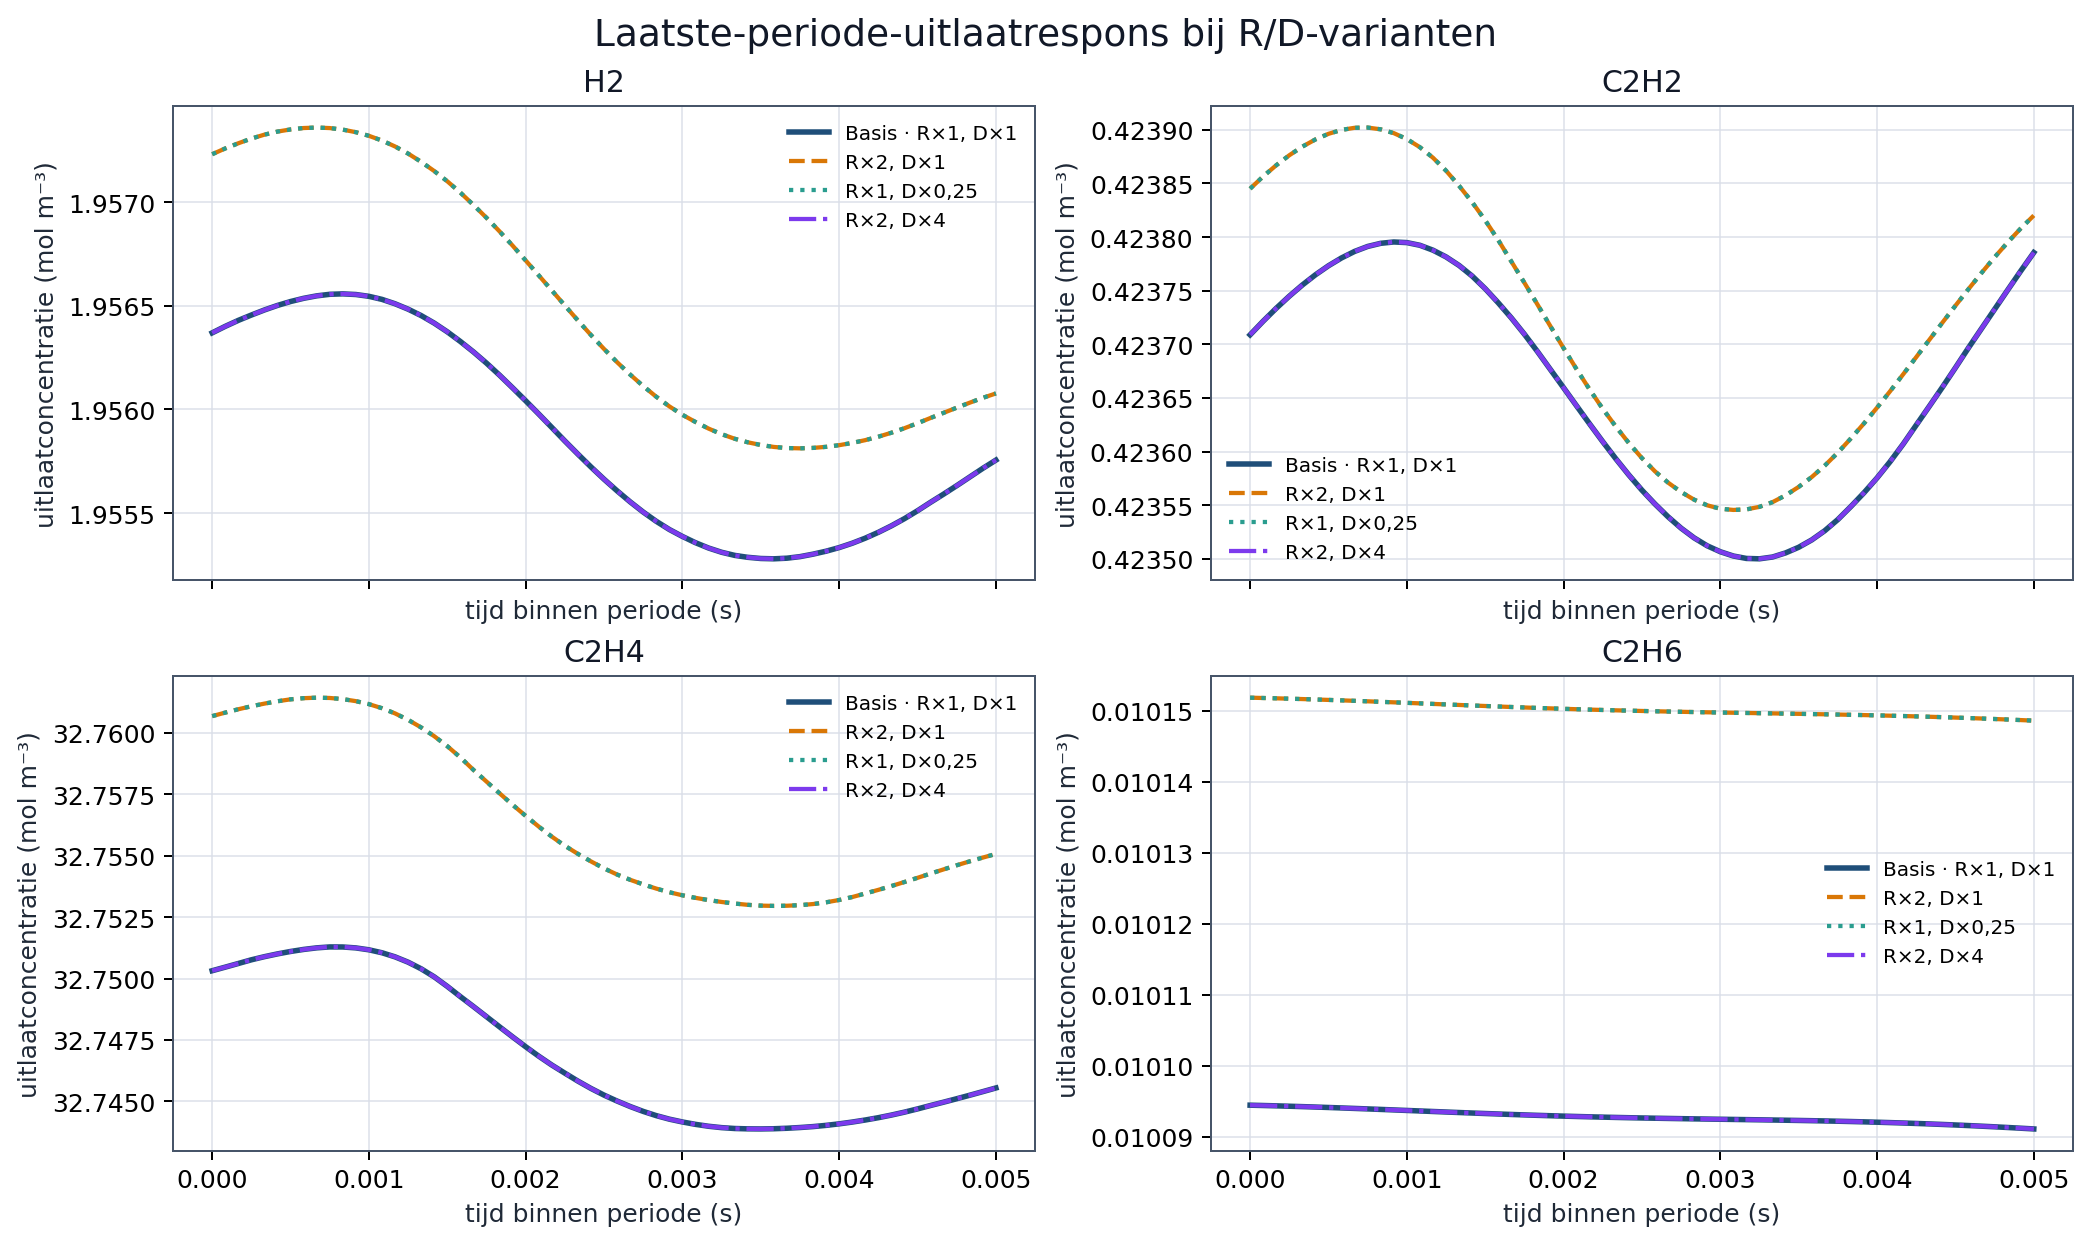

Figuur opgeslagen: notebooks/figures/radius_diffusivity_comparison.png


In [9]:
case_specs = (
    ("Basis · R×1, D×1", 1.0, 1.0),
    ("R×2, D×1", 2.0, 1.0),
    ("R×1, D×0,25", 1.0, 0.25),
    ("R×2, D×4", 2.0, 4.0),
)
case_results = []
for index, (label, radius_factor, diffusivity_factor) in enumerate(case_specs):
    result = baseline if index == 0 else run_case(radius_factor, diffusivity_factor)
    result["label"] = label
    result["outlet_last_cycle"] = result["trajectory"].bulk[-1, :, -1, :]
    case_results.append(result)
    print(
        f"{label}: {result['elapsed_s']:.2f} s · "
        f"nfev={result['solution'].nfev} · "
        f"min C={result['solution'].y.min():.4g} mol m⁻³"
    )

case_labels = tuple(result["label"] for result in case_results)
outlet_by_case = np.stack([result["outlet_last_cycle"] for result in case_results])
figure, _ = plot_parameter_comparison(
    phase, outlet_by_case, SPECIES_NAMES, case_labels
)
export_figure(figure, "radius_diffusivity_comparison.png")

In [10]:
comparison_rows = []
for result in case_results:
    model = result["model"]
    radius = model.grid.r_p
    d_c2h2 = model.diffusivities[Gas.C2H2]
    bare_time = radius**2 / d_c2h2
    pore_time = model.derived.particle_porosity * bare_time
    acetylene = result["outlet_last_cycle"][:, SPECIES_NAMES.index("C2H2")]
    mean_acetylene = np.trapezoid(acetylene, x=phase) / PERIOD
    half_swing = 0.5 * np.ptp(acetylene)
    comparison_rows.append(
        (result["label"], radius * 1e6, d_c2h2, bare_time * 1e3,
         pore_time * 1e3, mean_acetylene, half_swing)
    )

header = (
    "| Geval | R (µm) | Dₑ,C₂H₂ (m²/s) | R²/Dₑ (ms) | εₚR²/Dₑ (ms) | "
    "Gem. C₂H₂ uitlaat | Halve uitlaatswing C₂H₂ |\n"
    "|---|---:|---:|---:|---:|---:|---:|"
)
body = "\n".join(
    f"| {label} | {radius:.1f} | {diffusivity:.3e} | {bare:.3f} | "
    f"{pore:.3f} | {mean:.5g} | {swing:.5g} |"
    for label, radius, diffusivity, bare, pore, mean, swing in comparison_rows
)
display(Markdown(header + "\n" + body + "\n\nConcentraties in mol m⁻³."))


def relative_curve_difference(candidate, reference):
    scale = np.maximum(np.max(np.abs(reference), axis=0), np.finfo(float).tiny)
    return np.max(np.abs(candidate - reference), axis=0) / scale


for a, b in ((1, 2), (0, 3)):
    relative = relative_curve_difference(
        case_results[a]["outlet_last_cycle"], case_results[b]["outlet_last_cycle"]
    )
    print(
        f"Max. relatieve curve-afwijking {case_labels[a]} ↔ {case_labels[b]}: "
        f"{relative.max():.3e} (over alle gassen)"
    )

| Geval | R (µm) | Dₑ,C₂H₂ (m²/s) | R²/Dₑ (ms) | εₚR²/Dₑ (ms) | Gem. C₂H₂ uitlaat | Halve uitlaatswing C₂H₂ |
|---|---:|---:|---:|---:|---:|---:|
| Basis · R×1, D×1 | 75.0 | 2.444e-06 | 2.302 | 1.151 | 0.42366 | 0.00014773 |
| R×2, D×1 | 150.0 | 2.444e-06 | 9.207 | 4.603 | 0.42372 | 0.00017828 |
| R×1, D×0,25 | 75.0 | 6.110e-07 | 9.207 | 4.603 | 0.42372 | 0.00017828 |
| R×2, D×4 | 150.0 | 9.775e-06 | 2.302 | 1.151 | 0.42366 | 0.00014773 |

Concentraties in mol m⁻³.

Max. relatieve curve-afwijking R×2, D×1 ↔ R×1, D×0,25: 0.000e+00 (over alle gassen)
Max. relatieve curve-afwijking Basis · R×1, D×1 ↔ R×2, D×4: 0.000e+00 (over alle gassen)


## Wat is getest en wat blijft open?

De repositorytests controleren onder andere:

- de conservatieve radiale eindige-volume-operator en de gelijk-en-tegengestelde bulk/pelletuitwisseling bij uitgeschakelde reactie;
- dat de pelletreactie niet dubbel in de bulkbron wordt geteld;
- de eenheidsconversie van de Fuller-diffusiviteit, de inert-partiaaldruk en de positieve begrenzing van een periodieke TVD2-run;
- de settling-analyse en notebookfiguurhelpers.

De uitgevoerde integratie is een computationele smoke check, geen vergelijking met een gemeten BEP-respons. Deze voorbeeldrun gebruikt slechts vier axiale en vijf radiale cellen; er is hier geen roosteronafhankelijkheid van de volledige reactorrespons aangetoond. Verhoog de resolutie en vervang de gemarkeerde aannames door BEP-specifieke waarden voordat je kwantitatieve ontwerp- of validatieclaims maakt.